In [ ]:
%load_ext autoreload
%autoreload 2

# Design

> What the assay can see, and how to choose a library and a vector that see what you care about.

In [ ]:
#| default_exp design

In [ ]:
#| hide
from nbdev.showdoc import *
from fastcore.test import test_eq, test_close, test_fail

In [ ]:
#| export
import re
import numpy as np
import pandas as pd
from scipy.stats import beta, binom
from randseq.coding import encode_library, _pattern_window_codes, _decode_motif_codes
from randseq.utils import revcomp, get_patterns, _custom_motif_to_regex

In [ ]:
#| hide
import os
import matplotlib.pyplot as plt
from randseq.core import find_restricted_motifs
from randseq.coding import _motif_occurrences, _pattern_is_self_rc, _rc_code_table
from randseq.utils import calculate_log2fc, get_lib_seq_context, get_custom_motif_presence_in_library
from randseq.example_data import get_example_data_dir, get_example_backbone

Before an experiment, two questions: which motifs can this library call (sections 1 to 3), and
which does the vector hide (section 4)? After one, the same numbers say how much a motif *not*
found means (section 5).

The examples use the two libraries that ship with the package, read here straight from their
count tables:

In [ ]:
data_path = get_example_data_dir()
counts_20 = pd.read_csv(os.path.join(data_path, "countsTable.csv.gz"), index_col=0)
counts_150 = pd.read_csv(os.path.join(data_path, "counts_panel.csv.gz"), index_col=0)
flanks_20 = ("GTCCTAGGTATAATACTAGT", "GTTTTAGAGCTAGAAATAGC")     # vector sequence either side
flanks_150 = ("GTCTAGGGCGGCGGTAAAAC", "ACTAGAGCACCAGAAGTCTA")    # of the insert
libraries = {"20 nt": (list(counts_20.index), flanks_20),
             "150 nt": (list(counts_150.index), flanks_150)}
for name, (inserts, _) in libraries.items():
    lengths = pd.Series([len(s) for s in inserts])
    typical = lengths.mode()[0]
    print(f"{name} library: {len(inserts):,} inserts, {(lengths == typical).mean():.0%} of them "
          f"{typical} nt (shortest {lengths.min()}, longest {lengths.max()})")

20 nt library: 11,629 inserts, 100% of them 20 nt (shortest 20, longest 20)
150 nt library: 34,217 inserts, 92% of them 150 nt (shortest 8, longest 151)


## What sets detectability

A motif is called by contrasting the plasmids that carry it with those that do not, so **both
groups have to exist and both have to be large enough**. Three numbers set their sizes before any
data is collected: the library size `N`, the insert length `L`, and the motif's architecture --
its `k` defined bases spread over a width `w`. `CACNNNNGTAT`, pattern `(3, 4, 4)`, has `k = 7`
and `w = 11`.

An insert has `L - w + 1` windows on each strand, each matching a given motif with chance
`4**-k`, so it carries the motif with chance `1 - (1 - 4**-k)**(2 * (L - w + 1))`. `N` times
that is the expected number of carriers; the rest of the library is the motif-free group.

In [ ]:
#| export
def carrier_fraction(k, L, width=None, palindrome=False):
    """Chance that a random sequence of length `L` carries a given motif of `k` defined bases
    spread over `width` positions (default `k`, a contiguous site), on either strand.

    `L` may be a list of lengths, for a library whose inserts vary; the result is the mean over
    them. A palindrome reads the same on both strands, so it has one strand's chances.
    """
    windows = np.maximum(np.asarray(L) - (width or k) + 1, 0)
    return float(np.mean(1 - (1 - 4.0 ** -k) ** ((1 if palindrome else 2) * windows)))

In [ ]:
# CACNNNNGTAT (k = 7 over w = 11) in a 20 nt insert and in a 150 nt one
carrier_fraction(7, 20, width=11), carrier_fraction(7, 150, width=11)

(0.0012199955789821137, 0.016945153436759286)

In [ ]:
#| hide
# A 6 bp sequence is one window on each strand: two chances of 4**-6.
test_close(carrier_fraction(6, 6), 1 - (1 - 4**-6) ** 2)
# The width sets the windows, not the defined bases: CACNNNNGTAT in 20 nt has 10 per strand.
test_close(carrier_fraction(7, 20, width=11), 1 - (1 - 4**-7) ** 20)
# A palindrome such as GGTACC has one strand's chances.
test_close(carrier_fraction(6, 20, palindrome=True), 1 - (1 - 4**-6) ** 15)
# A sequence shorter than the motif cannot carry it, and a list of lengths is averaged.
test_eq(carrier_fraction(6, 5), 0)
test_close(carrier_fraction(6, [20, 150]), (carrier_fraction(6, 20) + carrier_fraction(6, 150)) / 2)

Inserts need not be one length. The scan reads whatever strings index the count table, and
`carrier_fraction` takes the lengths themselves: the 150 nt library's inserts run from 8 to 151 nt.

Against what the two libraries hold -- the carriers of every possible motif of a pattern, zeros
included, counted with the scan's own `_motif_occurrences`, in the inserts alone and with the vector
flanks the scan reads alongside them:

In [ ]:
def carriers_per_motif(sequences, pattern):
    "Carriers of every possible motif of `pattern`, zeros included; a motif and its reverse complement are one."
    k = pattern[0] + pattern[2]
    _, codes = _motif_occurrences(encode_library(sequences), pattern)
    n = np.bincount(codes, minlength=4 ** k)
    # a self-reverse-complementary pattern folds each motif onto the smaller code of the pair
    return n[np.arange(4 ** k) <= _rc_code_table(pattern)] if _pattern_is_self_rc(pattern) else n

rows = []
for name, (inserts, flanks) in libraries.items():
    lengths, flanked = [len(s) for s in inserts], get_lib_seq_context(inserts, *flanks)
    for p in [(6, 0, 0), (7, 0, 0), (3, 4, 4), (3, 8, 4), (4, 4, 4), (4, 8, 4)]:
        inside = carriers_per_motif(inserts, p)
        rows.append({"library": name, "pattern": str(p),
                     "expected": len(inserts) * carrier_fraction(p[0] + p[2], lengths, sum(p)),
                     "mean": inside.mean(), "median": np.median(inside),
                     "median with flanks": np.median(carriers_per_motif(flanked, p))})
carriers = pd.DataFrame(rows).set_index(["library", "pattern"])
carriers.round(1)

expected    mean  median  median with flanks
library pattern                                                
20 nt   (6, 0, 0)      84.9    83.4    77.0               107.0
        (7, 0, 0)      19.9    19.8    17.0                24.0
        (3, 4, 4)      14.2    14.1    13.0                23.0
        (3, 8, 4)       8.5     8.5     8.0                19.0
        (4, 4, 4)       3.2     3.2     3.0                 5.0
        (4, 8, 4)       1.8     1.8     1.0                 4.0
150 nt  (6, 0, 0)    2333.9  2269.7  1967.0              2090.0
        (7, 0, 0)     594.9   590.4   505.0               533.0
        (3, 4, 4)     578.5   573.8   492.0               542.0
        (3, 8, 4)     562.0   557.5   478.0               559.0
        (4, 4, 4)     144.5   143.6   119.0               131.0
        (4, 8, 4)     140.3   139.5   115.0               135.0

- **The expectation is the mean**, to within 3%. The median motif has fewer carriers, by up to a
  fifth on the 150 nt library: base composition is not uniform, so motifs made of the commoner
  bases take more than their share.
- **Width matters, not only defined bases.** In 20 nt inserts a `(3, 8, 4)` site has 6 windows
  per strand against 14 for a contiguous 7 bp site, and so 8.5 carriers against 20. In 150 nt
  inserts the difference all but vanishes.
- **Sites across the junction count.** The flanks are read with the insert, so a site the vector
  half-completes needs only the rest from the insert. On short inserts that is a large share: a
  `(4, 4, 4)` motif of the 20 nt library has a median of 5 carriers with the flanks, 3 without. Which motifs
  gain depends on what the flanks spell. The panel's left flank ends in `AAAC`, so every insert that
  starts `NNNNGTC` completes B156's site `AAACNNNNGTC`:

In [ ]:
log2fc_150 = calculate_log2fc(counts_150, reference_column="Control_R1", count_threshold=20)
measured = list(log2fc_150.index)          # the plasmids the analysis sees
with_flanks = get_custom_motif_presence_in_library(measured, *flanks_150, ["AAACNNNNGTC"]).sum().item()
inside = get_custom_motif_presence_in_library(measured, "", "", ["AAACNNNNGTC"]).sum().item()
print(f"AAACNNNNGTC: {with_flanks} carriers, {with_flanks - inside} of them only across the junction")

AAACNNNNGTC: 894 carriers, 382 of them only across the junction


The expectation assumes random inserts, and a library can be biased against a site. `GGTCTC`
(BsaI) and `GAAGAC` (BbsI) are both 6 bp and not palindromic, so each should have the same number
of carriers:

In [ ]:
for name, (inserts, _) in libraries.items():
    present = get_custom_motif_presence_in_library(inserts, "", "", ["GGTCTC", "GAAGAC"]).sum()
    expected = len(inserts) * carrier_fraction(6, [len(s) for s in inserts])
    print(f"{name}: {expected:,.0f} expected; " + ", ".join(f"{m} {n:,}" for m, n in present.items()))

20 nt: 85 expected; GGTCTC 9, GAAGAC 75
150 nt: 2,334 expected; GGTCTC 65, GAAGAC 1,781


`GGTCTC` is ten to thirty-five times rarer than chance in both libraries. A site that library
construction selects against -- as an assembly enzyme's own site is -- is rare whatever `N` and `L`
predict, so count a site you care about in the input library before relying on the expectation.

## The calling floor

A motif is called when both hold:

- **q < 0.05.** Its p-value is the binomial probability that at least this many of its carriers
  deplete if each depletes at its GC-matched background rate; q adjusts it (Benjamini-Hochberg)
  over every motif the scan tested in the sample.
- **The one-sided 95% lower bound on its depleted fraction is at least 0.5**
  (`score_thr`): most of its carriers are depleted, with confidence.

A motif is scored only with `min_support = 5` carriers, the smallest number that can
meet the second condition: with every carrier depleted, 4 carriers bound the fraction at 0.47 and 5
at 0.55.

The correction turns the first condition into a p-value cutoff that depends on the sample: the more
motifs deplete, the more lenient it is. Over the 35 shipped samples it runs from 1.4 × 10⁻⁶
(`EDL933_dRM_R1`, which restricts nothing) to 2.6 × 10⁻⁴ (E1114 on the 20 nt library); K12 on the
20 nt library has no motif at q < 0.05. `min_carriers` finds the fewest carriers that meet both
conditions at a given cutoff.

In [ ]:
#| export
def min_carriers(fraction_depleted, background, cutoff=1e-4, score_thr=0.5, min_support=5):
    """Fewest carriers at which a motif with this depleted fraction is called; None if no number
    up to 20,000 is enough.

    The two calling conditions of `find_restricted_motifs`, with the Benjamini-Hochberg correction
    replaced by the p-value `cutoff` it leaves in a sample: the depleted count has a binomial
    p-value at most `cutoff` against `background`, and the one-sided 95% lower bound on the
    depleted fraction reaches `score_thr`.
    """
    n = np.arange(min_support, 20001)
    k = np.ceil(fraction_depleted * n)
    ok = (binom.sf(k - 1, n, background) <= cutoff) & (beta.ppf(0.05, k, n - k + 1) >= score_thr)
    return int(n[ok][0]) if ok.any() else None

In [ ]:
#| hide
# A site that depletes every carrier needs only min_support: the bound binds, not q.
test_eq(min_carriers(1.0, 0.1), 5)
# One that depletes 60% needs 62, whatever the background: below that the bound stays under 0.5.
test_eq([min_carriers(0.6, b) for b in (0.03, 0.1, 0.2)], [62, 62, 62])
# In a noisy sample with a strict cutoff q binds instead, and more carriers are needed.
test_eq(min_carriers(1.0, 0.35, cutoff=1e-6), 14)
# The example panel's calls quoted below: RM sites at 84% (background 0.14) and 92% (0.19) need 5
# and 6, HS's BREX site 30, 381A's CCTNAGG 15.
test_eq([min_carriers(0.837, 0.14), min_carriers(0.918, 0.19)], [5, 6])
test_eq([min_carriers(0.638, 0.115), min_carriers(0.736, 0.295)], [30, 15])
# A motif depleted half the time can never show that most of its carriers are.
test_eq(min_carriers(0.5, 0.1), None)

In [ ]:
fractions, backgrounds = (1.0, 0.9, 0.8, 0.7, 0.6, 0.55), (0.03, 0.1, 0.2, 0.35)
pd.concat({f"cutoff {c:g}": pd.DataFrame([[min_carriers(f, b, c) for b in backgrounds] for f in fractions],
                                          index=pd.Index(fractions, name="fraction depleted"),
                                          columns=pd.Index(backgrounds, name="background"))
           for c in (2e-4, 1e-6)}, axis=1)

cutoff 0.0002                cutoff 1e-06               
background                 0.03 0.10 0.20 0.35         0.03 0.10 0.20 0.35
fraction depleted                                                         
1.00                          5    5    6    9            5    7    9   14
0.90                          5    5    6    9            5    7    9   17
0.80                          8    8    8   14            8    8   14   27
0.70                         13   13   13   23           13   13   19   43
0.60                         62   62   62   62           62   62   62   87
0.55                        262  262  262  262          262  262  262  262

**The confidence bound sets the floor** unless the background is high and the cutoff strict: 5
carriers when every carrier is destroyed, 13 at 70% depleted, 62 at 60% and 262 at 55%, at any
background up to 0.1. In a noisy sample where few motifs deplete, q takes over: at a background of
0.35 and a cutoff of 10⁻⁶ a complete site needs 14 carriers and a 60% one 87. After median normalisation, the
shipped samples deplete 3% to 15% of their plasmids on the 20 nt library and 9% to 35% on the
150 nt one (381A is the 35%).

So the floor is set by the system more than by the sample. The RM sites called on the example panel
(`00_core`, *The example panel at a glance*) deplete 84% to 100% of their carriers and need 5 or 6;
HS's BREX site depletes 64% of its carriers (section 4) and needs 30; 381A's `CCTNAGG`, 74% against
a background of 0.30, needs 15.

## Planning a library

`plan_library` puts the two together: for a library of `N` inserts of length `L`, per
architecture, the expected carriers of a motif, whether a strong site (every carrier depleted) and a
weak one (60%) would be called, and the library size that would make each callable.

The defaults, a background of 0.1 and a cutoff of 10⁻⁴, are typical of the shipped samples. Two
simplifications, both on the safe side. Carriers are counted with the site inside the insert,
the floor for every motif; sites across the junction add to some. And a motif's carriers are part
of every GC class, so their own depletion raises the background they are tested against: a motif on
a share `p` of the library, depleting a fraction `f`, is tested against roughly
`background + p * (f - background)`. That changes no verdict for the patterns searched by default,
but it is why a motif carried by every plasmid -- one in the vector (section 4) -- can never be called.

In [ ]:
#| export
def plan_library(N, L, patterns=None, background=0.1, cutoff=1e-4, weak=0.6, backbone=None):
    """What a library of `N` inserts can call, per motif architecture.

    `L` is the insert length, or the lengths themselves when they vary. For each pattern of
    `patterns` (default `get_patterns()`): `carriers`, the expected carriers of a motif with its
    site inside the insert, and `non_carriers`; then, for a site depleting every carrier
    (`strong`) and one depleting a fraction `weak` of them, the carriers needed to call it
    (`min_carriers` at `background` and `cutoff`), whether the library has them, and the library
    size that would (`N_strong`, `N_weak`). With a `backbone` sequence, `masked` is the share of
    the pattern's motifs the vector already carries (`backbone_masking_summary`).
    """
    patterns = get_patterns() if patterns is None else patterns
    rows = []
    for p in patterns:
        k, w = p[0] + p[2], sum(p)
        frac = carrier_fraction(k, L, w)
        row = dict(pattern=str(p), defined_bases=k, width=w, carriers=N * frac, non_carriers=N * (1 - frac))
        for site, f in (("strong", 1.0), ("weak", weak)):
            # the carriers' own depletion is part of the background they are tested against
            need = min_carriers(f, background + frac * (f - background), cutoff)
            row[f"need_{site}"] = need
            row[site] = need is not None and N * frac >= need
            row[f"N_{site}"] = int(np.ceil(need / frac)) if need and frac > 0 else None
        rows.append(row)
    out = pd.DataFrame(rows)
    for c in ("need_strong", "N_strong", "need_weak", "N_weak"):
        out[c] = out[c].astype("Int64")
    if backbone is not None:
        out["masked"] = backbone_masking_summary(backbone, patterns).fraction.to_numpy()
    return out

In [ ]:
plan_20 = plan_library(11629, 20).set_index("pattern")      # the 20 nt library
plan_20.loc[["(6, 0, 0)", "(2, 8, 4)", "(7, 0, 0)", "(4, 4, 4)"],
            ["carriers", "need_strong", "strong", "need_weak", "weak", "N_weak"]].round(1)

,carriers,need_strong,strong,need_weak,weak,N_weak
pattern,,,,,,
"(6, 0, 0)",84.9,5,True,62,True,8496
"(2, 8, 4)",39.7,5,True,62,False,18169
"(7, 0, 0)",19.9,5,True,62,False,36309
"(4, 4, 4)",3.2,5,False,62,False,225765


In [ ]:
#| hide
# carriers is N times carrier_fraction, at the pattern's own width
test_close(plan_20.loc["(3, 4, 4)", "carriers"], 11629 * carrier_fraction(7, 20, 11))
# a strong 7-base site is within reach of 20 nt inserts, an 8-base one is not
test_eq(plan_20.loc[["(7, 0, 0)", "(4, 4, 4)"], "strong"].tolist(), [True, False])
# a weak site needs about 60 carriers: a 6 bp site has them, a 6-base site with an 8 nt gap does not
test_eq(plan_20.loc[["(6, 0, 0)", "(2, 8, 4)"], "weak"].tolist(), [True, False])
# N_weak is the smallest library that reaches need_weak
r, p = plan_20.loc["(4, 4, 4)"], carrier_fraction(8, 20, 12)
assert r.N_weak * p >= r.need_weak > (r.N_weak - 1) * p

On the two example libraries, with their measured insert lengths, grouped by defined bases (the
count of patterns at which each kind of site is callable):

In [ ]:
plans = {name: plan_library(len(inserts), [len(s) for s in inserts])
         for name, (inserts, _) in libraries.items()}
pd.concat({name: plan.groupby("defined_bases").agg(
               patterns=("pattern", "size"), fewest_carriers=("carriers", "min"),
               most_carriers=("carriers", "max"), strong=("strong", "sum"), weak=("weak", "sum"))
           for name, plan in plans.items()}).round(1)

patterns  fewest_carriers  most_carriers  strong  weak
       defined_bases                                                        
20 nt  5                     9            180.4          358.0       9     9
       6                    17             39.7           84.9      17     9
       7                     9              8.5           19.9       9     0
       8                     8              1.8            4.3       0     0
150 nt 5                     9           8069.9         8475.5       9     9
       6                    17           2209.1         2333.9      17    17
       7                     9            562.0          594.9       9     9
       8                     8            140.3          147.6       8     8

**The 150 nt library calls every architecture `get_patterns()` searches, weak sites included**: its
sparsest pattern, `(4, 8, 4)`, still expects 140 carriers per motif. **The 20 nt library calls
strong sites of 5 to 7 defined bases but no 8-base site** (1.8 to 4.3 carriers per motif inside the
insert), **and weak sites only up to 6 defined bases on the narrower patterns.** A negative for a
weak site, or for any 8-base site, on the 20 nt library means nothing -- unless the flanks complete
part of it.

The inverse question, the library size each would need for an 8-base site:

In [ ]:
pd.concat({name: plan.query("defined_bases == 8").set_index("pattern")[["carriers", "N_strong", "N_weak"]]
           for name, plan in plans.items()}, axis=1).round(1)

20 nt                    150 nt                
          carriers N_strong  N_weak carriers N_strong N_weak
pattern                                                     
(4, 1, 4)      4.3    13656  169332    147.6     1159  14372
(4, 2, 4)      3.9    14897  184722    146.6     1168  14474
(4, 3, 4)      3.5    16387  203192    145.5     1176  14577
(4, 4, 4)      3.2    18207  225765    144.5     1184  14682
(4, 5, 4)      2.8    20483  253982    143.5     1193  14788
(4, 6, 4)      2.5    23409  290260    142.4     1202  14896
(4, 7, 4)      2.1    27309  338632    141.4     1211  15006
(4, 8, 4)      1.8    32771  406352    140.3     1220  15117

For long sites the insert is the cheap lever. From 20 to 150 nt a `(4, 8, 4)` site goes from 5
windows per strand to 135, and the 20 nt library would need about 400,000 inserts to match the weak
site the 150 nt library sees with 34,000. Lengthening the insert also raises the share of plasmids
carrying each short motif -- 25% of 150 nt inserts carry a given 5 bp motif -- and with it that
motif's own background; at 4 defined bases (not searched by default) it would be 68%.

## Plasmid size and the vector

Every plasmid in the library carries the vector. A motif in the backbone is in every plasmid, so
there is no motif-free group and the background it is tested against is its own depletion. For a
system that one site suffices to restrict -- the common case for Type I and Type II RM -- the
backbone copy already saturates it, and the insert copies add nothing the assay can see. The vector
is a design choice, and its size sets how much of the search space it hides.

### What the backbone hides

`pMin`, the 150 nt library's vector, is a 2.2 kb mobilisable plasmid. The library is cloned in place of a `ccdB` cassette, so what
every library member shares is the 2,214 bp from one side of the insert round to the other, which
ships as `pMin_backbone.fasta`.

In [ ]:
backbone = get_example_backbone()
print(f"{len(backbone)} bp; starts at the right flank, ends at the left flank")
print(f"  {backbone[:20]} ... {backbone[-20:]}")

2214 bp; starts at the right flank, ends at the left flank
  ACTAGAGCACCAGAAGTCTA ... GTCTAGGGCGGCGGTAAAAC


In [ ]:
#| export
def _motif_site_count(sequence, motif, circular=False):
    """How many times `motif` occurs as a site in `sequence`, on either strand.

    A site is counted once however it reads, which is what an enzyme sees, so a palindromic
    motif is not counted twice. `circular=True` also finds sites spanning the origin.
    """
    seq = sequence.upper()
    if circular and len(seq) >= len(motif):
        seq = seq + seq[:len(motif) - 1]
    pat = _custom_motif_to_regex(motif)
    n = len(re.findall(f"(?={pat})", seq))
    rc_motif = revcomp(motif)
    if rc_motif != motif:                       # not a palindrome: the other reading is distinct
        n += len(re.findall(f"(?={_custom_motif_to_regex(rc_motif)})", seq))
    return n

In [ ]:
#| hide
# A site is counted on either strand, once: an enzyme sees one site however it reads.
test_eq(_motif_site_count("AAAGGTCTCAAA", "GGTCTC"), 1)
test_eq(_motif_site_count("AAAGAGACCAAA", "GGTCTC"), 1)        # the same site, other strand
test_eq(_motif_site_count("GGTCTCAAGAGACC", "GGTCTC"), 2)
test_eq(_motif_site_count("AAAAAAAA", "GGTCTC"), 0)
# A palindrome reads identically both ways and is one site, not two.
test_eq(_motif_site_count("AAAGGTACCAAA", "GGTACC"), 1)
# IUPAC codes and N are honoured, since called motifs use them.
test_eq(_motif_site_count("AAACACTTTTGTATAAA", "CACNNNNGTAT"), 1)
test_eq(_motif_site_count("AAACACTTTTGTACAAA", "CACNNNNGTAY"), 1)
# A site spanning the origin is found only when asked: a library backbone is linear.
test_eq(_motif_site_count("CTCAAAAAAAAAGGT", "GGTCTC", circular=False), 0)
test_eq(_motif_site_count("CTCAAAAAAAAAGGT", "GGTCTC", circular=True), 1)

In [ ]:
#| export
def backbone_motif_counts(backbone, patterns, circular=False):
    """Every motif of `patterns` that the backbone already carries, and how many copies.

    `circular=False` is right for a library backbone, which is a linear stretch running from one
    side of the insert round to the other -- the insert closes it, so it is not circular on its
    own. Pass `circular=True` for a whole plasmid.

    Returns 'motif', 'pattern' and 'copies', one row per motif carried at least once.
    """
    rows = []
    for pattern in patterns:
        d1, spacer, d2 = pattern
        width = d1 + spacer + d2
        seq = backbone.upper()
        if circular and len(seq) >= width:
            seq = seq + seq[:width - 1]
        if len(seq) < width:
            continue
        f, r = encode_library([seq])
        n_codes = 4 ** (d1 + d2)
        counts = np.zeros(n_codes + 1, dtype=np.int64)
        for arr in (f, r):
            codes = _pattern_window_codes(arr, pattern).ravel()
            counts += np.bincount(codes, minlength=n_codes + 1)
        present = np.flatnonzero(counts[:n_codes])
        if not len(present):
            continue
        for motif, c in zip(_decode_motif_codes(present, pattern), counts[present]):
            # a palindrome reads identically on both strands, so each site was counted twice
            rows.append(dict(motif=motif, pattern=str(pattern),
                             copies=int(c) // 2 if revcomp(motif) == motif else int(c)))
    return pd.DataFrame(rows, columns=["motif", "pattern", "copies"])

In [ ]:
_bb6 = backbone_motif_counts(backbone, [(6, 0, 0)]).set_index("motif")
_bb6.sort_values("copies", ascending=False).head()

,pattern,copies
motif,,
TTTTTT,"(6, 0, 0)",13
AAAAAA,"(6, 0, 0)",13
TTTTTC,"(6, 0, 0)",10
GAAAAA,"(6, 0, 0)",10
AAAAAG,"(6, 0, 0)",9


In [ ]:
#| hide
# On pMin: HS's BREX site GGTAAG is in the backbone twice, listed under both spellings.
test_eq(_bb6.loc[["GGTAAG", "CTTACC"], "copies"].tolist(), [2, 2])

In [ ]:
#| hide
# The scan-based counter and the regex-based one must agree, motif for motif.
_bb = "".join(np.random.default_rng(0).choice(list("ACGT"), 400))
_c = backbone_motif_counts(_bb, [(6, 0, 0), (3, 4, 4)])
assert len(_c) and (_c.copies > 0).all()
for _r in _c.sample(25, random_state=0).itertuples():
    test_eq(_r.copies, _motif_site_count(_bb, _r.motif))
# A backbone with no room for the pattern yields nothing rather than raising.
test_eq(len(backbone_motif_counts("ACGT", [(6, 0, 0)])), 0)

In [ ]:
#| export
def backbone_masking_summary(backbone, patterns, circular=False):
    """Per pattern, how much of the searchable motif space the backbone already occupies.

    A motif the backbone carries is one the assay is unlikely to report for this vector, so this
    is the coverage of the search space -- the share of possible answers ruled out before any
    data is collected.
    """
    counts = backbone_motif_counts(backbone, patterns, circular=circular)
    carried = counts.groupby("pattern").size() if len(counts) else pd.Series(dtype=int)
    rows = []
    for pattern in patterns:
        space = 4 ** (pattern[0] + pattern[2])
        n = int(carried.get(str(pattern), 0))
        rows.append(dict(pattern=str(pattern), defined_bases=pattern[0] + pattern[2],
                         motifs=space, carried=n, fraction=n / space))
    return pd.DataFrame(rows)

In [ ]:
#| hide
# The summary counts, per pattern, the motifs backbone_motif_counts lists, out of 4**k possible.
_s = backbone_masking_summary(_bb, [(6, 0, 0)])
test_eq(int(_s.motifs.iloc[0]), 4096)
test_eq(int(_s.carried.iloc[0]), len(_c[_c.pattern == "(6, 0, 0)"]))
test_eq(float(_s.fraction.iloc[0]), _s.carried.iloc[0] / 4096)

A backbone is one more sequence that every plasmid carries, so the share of a pattern's motifs it
holds is `carrier_fraction(k, B, w)` for a backbone of length `B`: about `1 - exp(-2B / 4**k)`.
Against pMin's exact counts on the patterns `get_patterns()` searches:

In [ ]:
B, patterns = len(backbone), get_patterns()
summary = backbone_masking_summary(backbone, patterns)
summary["expected"] = [carrier_fraction(p[0] + p[2], B, sum(p)) for p in patterns]
by_size = summary.groupby("defined_bases").agg(patterns=("pattern", "size"), masked=("fraction", "mean"),
                                               expected=("expected", "mean"))
print(by_size.to_string(float_format=lambda x: f"{x:.1%}"))
print(f"\nover the whole searched space: {summary.carried.sum():,} of {summary.motifs.sum():,} "
      f"motifs = {summary.carried.sum() / summary.motifs.sum():.1%} already carried")

               patterns  masked  expected
defined_bases                            
5                     9   97.6%     98.7%
6                    17   62.9%     65.9%
7                     9   22.8%     23.6%
8                     8    6.4%      6.5%

over the whole searched space: 119,913 of 750,592 motifs = 16.0% already carried


The approximation is within about 3 points at every size; a real backbone holds slightly fewer distinct
motifs than a random sequence because its composition is uneven (pMin has 13 copies of `AAAAAA`).
So the masking of any vector can be read off its length:

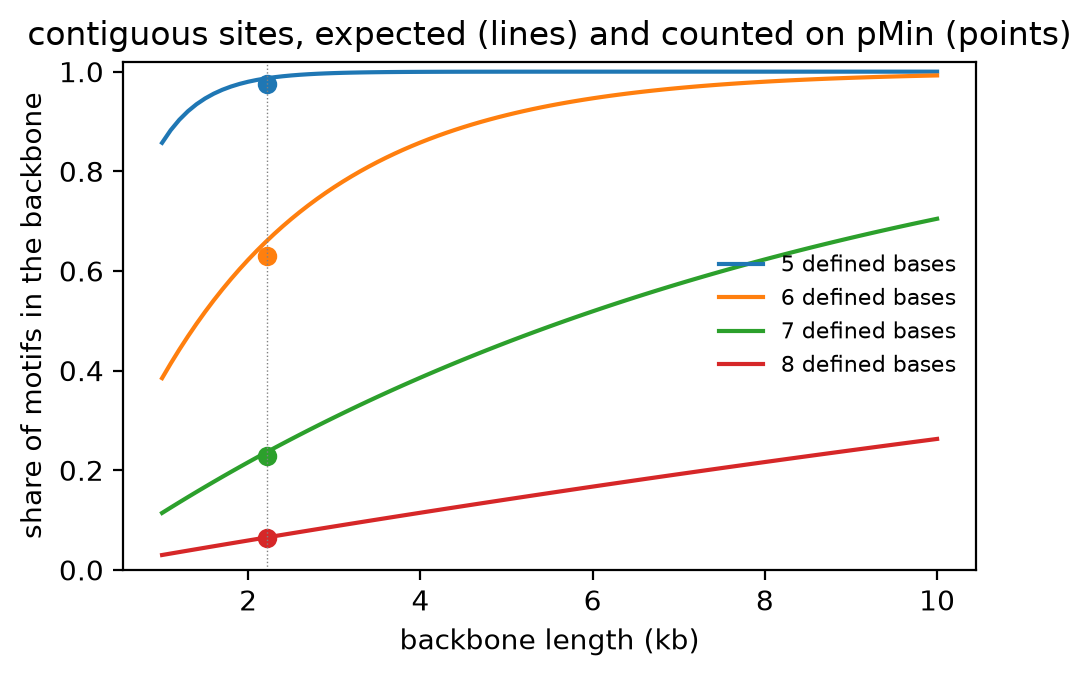

In [ ]:
sizes = np.arange(1000, 10001, 100)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for k in range(5, 9):
    line, = ax.plot(sizes / 1000, [carrier_fraction(k, b) for b in sizes], label=f"{k} defined bases")
    ax.plot(B / 1000, by_size.masked[k], "o", color=line.get_color())
ax.axvline(B / 1000, color="grey", lw=0.5, ls=":")
ax.set(xlabel="backbone length (kb)", ylabel="share of motifs in the backbone", ylim=(0, 1.02),
       title="contiguous sites, expected (lines) and counted on pMin (points)")
ax.legend(frameon=False, fontsize=8)
plt.show()

In [ ]:
pd.DataFrame({f"{b / 1000:.1f} kb": [f"{carrier_fraction(k, b):.0%}" for k in range(5, 9)]
              for b in (2214, 3000, 5000, 10000)},
             index=pd.Index(range(5, 9), name="defined bases"))

,2.2 kb,3.0 kb,5.0 kb,10.0 kb
defined bases,,,,
5,99%,100%,100%,100%
6,66%,77%,91%,99%
7,24%,31%,46%,70%
8,7%,9%,14%,26%


**Plasmid size is the cost.** At 2.2 kb pMin hides 98% of 5-base motifs, 63% of 6-base, 23% of
7-base and 6% of 8-base ones. A 5 kb vector would hide 91% of 6-base motifs and 46% of 7-base ones;
a 10 kb vector 99% and 70%, and a quarter of 8-base motifs. Short Type II sites are lost to almost
any vector; what a small vector buys is the 6- and 7-base sites. This runs opposite to the insert:
a short site is easy to find in the insert and probably in the vector already, a long bipartite site
the reverse.

`plan_library` reports both sides when given the backbone. For the 150 nt library on pMin:

In [ ]:
plan_pmin = plan_library(len(counts_150), [len(s) for s in counts_150.index], backbone=backbone)
plan_pmin.groupby("defined_bases")[["carriers", "strong", "weak", "masked"]].mean().round(3)

,carriers,strong,weak,masked
defined_bases,,,,
5,8273.190,1.0,1.0,0.976
6,2267.875,1.0,1.0,0.629
7,578.456,1.0,1.0,0.228
8,143.978,1.0,1.0,0.064


In [ ]:
#| hide
# masked is backbone_masking_summary's fraction, pattern for pattern
test_eq(plan_pmin.masked.tolist(), summary.fraction.tolist())

### Copies in the backbone add to the insert's

A backbone copy does not always hide a motif. When interference grows with the number of sites, as
it does for BREX, the insert's copies add to the backbone's: plasmids with an insert copy still
differ from those without, and the backbone copies can bring a plasmid closer to the threshold. So a
backbone copy is a reason to distrust a negative, not proof of one -- and where something other than
site number limits activity, removing it need not restore a signal either.

`annotate_backbone` adds the copy number to any table of motifs, a result or a list of sites to
check against a vector.

In [ ]:
#| export
def annotate_backbone(results_df, backbone, circular=False):
    """Add `backbone_copies` to a result table: copies of each reported motif in the backbone.

    0 is the expected value for anything the pipeline reported, since a motif the backbone
    carries is usually not detectable in the first place. A non-zero count is worth looking at:
    it means the motif was called *despite* the vector already carrying it, which happens when
    interference is density-dependent.
    """
    if results_df is None or len(results_df) == 0 or "motif" not in results_df.columns:
        return results_df
    out = results_df.copy()
    out["backbone_copies"] = [_motif_site_count(backbone, m, circular) for m in out["motif"]]
    return out

In [ ]:
# JJ1886's three calls on the panel, and the BREX site of E. coli HS
_called = pd.DataFrame({"motif": ["RTACNNNNGTG", "AAAGNNNNGTT", "GGTCTC", "GGTAAG"]})
_annotated = annotate_backbone(_called, backbone)
_annotated

,motif,backbone_copies
0,RTACNNNNGTG,0
1,AAAGNNNNGTT,0
2,GGTCTC,0
3,GGTAAG,2


In [ ]:
#| hide
# JJ1886's sites are absent from the vector; the BREX site is there twice.
test_eq(_annotated.backbone_copies.tolist(), [0, 0, 0, 2])
# The input table is not modified, and a table with nothing to annotate comes back as it was.
assert "backbone_copies" not in _called.columns
test_eq(len(annotate_backbone(_called.iloc[:0], backbone)), 0)
assert annotate_backbone(None, backbone) is None

HS's BREX site `GGTAAG` is in pMin twice, and is still called on the example panel:

In [ ]:
encoded_150 = encode_library(get_lib_seq_context(measured, *flanks_150))   # shared by the runs below

In [ ]:
#| output: false
hs = find_restricted_motifs(log2fc_150["HS_R1"], *flanks_150, encoded_library=encoded_150)

11 candidate(s) across all patterns; 3 remain after step 3.
2 candidate(s) whose score was borrowed:
    AGGTCTC <- CTTACC (without them: n=10, score=0.40)
    CGGCNGCCG <- CTTACC (without them: n=5, score=0.40)
1 motif(s) scored:
  GGTAAG (pattern (6, 0, 0)), FracDep: 0.64, AvgFC: -0.65, N: 1879
1 motif(s) called.


Scanning patterns: 100%|##########| 43/43 [00:03<00:00, 11.19it/s]


In [ ]:
hs

,motif,num_sequences,fraction_depleted,avg_log2fc,q_value
0,GGTAAG,1879,0.637573,-0.654037,0.0


In [ ]:
#| hide
# called although every plasmid carries two copies in the backbone
test_eq(hs.motif.tolist(), ["GGTAAG"])

### A second backbone

A motif is out of reach only if *every* backbone in use carries it. An unrelated second vector
hides an independent sample of the motif space, so it recovers a motif the first one masks with
chance about one minus its own masked fraction. A random sequence of pMin's composition and length
stands in for it here:

In [ ]:
second = "".join(np.random.default_rng(1).permutation(list(backbone)))   # pMin's bases, shuffled
both = backbone_motif_counts(backbone, patterns).merge(
    backbone_motif_counts(second, patterns), on=["motif", "pattern"], how="left", indicator=True)
both["defined_bases"] = both.motif.str.count("[ACGT]")
(both._merge == "left_only").groupby(both.defined_bases).mean().map("{:.0%}".format).to_frame(
    "masked by pMin, free in the second")

,"masked by pMin, free in the second"
defined_bases,
5,2%
6,34%
7,76%
8,93%


A second vector recovers most masked 7- and 8-base sites, a third of the masked 6-base ones and
almost no 5-base ones. For short sites the remedy is a smaller backbone, or one cleared of the sites
of interest; check either with `backbone_motif_counts`.

## Reading a negative result

No call for a site means the strain does not restrict it, or that the experiment could not see it.
Rule out the second before concluding the first:

1. **Is its architecture searched?** A site whose pattern is not in `patterns`
   cannot be found.
2. **Did it have the carriers?** `plan_library` gives the expectation and section 2 the floor:
   about 5 carriers for a site that destroys every carrier, about 60 for one that depletes 60%.
   Count the site in the measured library too (`get_custom_motif_presence_in_library`), since the
   library can be biased against it.
3. **Is it in the vector?** `annotate_backbone`: a backbone copy hides a site that one copy
   suffices to restrict.
4. **Was the threshold the default −0.5?** A stricter one misses weakly interfering systems such as
   HS's BREX (`log2fc_thr` in `find_restricted_motifs`).

A negative is strongest beside a matched positive, on the same library and vector: EDL933 calls its
RM site, and its isogenic RM knockout calls nothing.

In [ ]:
#| output: false
edl933 = {s: find_restricted_motifs(log2fc_150[s], *flanks_150, encoded_library=encoded_150).motif.tolist()
          for s in ("EDL933_R1", "EDL933_dRM_R1")}

9 candidate(s) across all patterns; 1 remain after step 3.
1 motif(s) scored:
  CACNNNNNNNCTGG (pattern (3, 7, 4)), FracDep: 0.91, AvgFC: -1.16, N: 277
1 motif(s) called.
0 motif(s) scored:
0 motif(s) called.


Scanning patterns: 100%|##########| 43/43 [00:02<00:00, 18.66it/s]


In [ ]:
edl933

{'EDL933_R1': ['CACNNNNNNNCTGG'], 'EDL933_dRM_R1': []}

In [ ]:
#| hide
test_eq(edl933, {"EDL933_R1": ["CACNNNNNNNCTGG"], "EDL933_dRM_R1": []})

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()